# 05 - Imbalance Handling

**Objective:** measure whether adjusting for class imbalance (3.5% fraud) improves the model relative to the baseline.

**Approach:** same LightGBM, same raw features, and same temporal splits as in the baseline. Only the imbalance strategy changes. Each configuration is trained with **3 seeds** and the mean ± standard deviation is compared, because we have already seen that a single run can be misleading (the PR-AUC variation between seeds is around 0.004).

**Strategies compared**
- No adjustment (baseline).
- `scale_pos_weight` = square root of the negative/positive ratio (moderate adjustment).
- `scale_pos_weight` = negative/positive ratio (full balance).
- Random undersampling of the majority class (20% of non-fraud cases are kept).

**Why not SMOTE:** it generates synthetic examples by interpolating between neighbors, which requires numerical features without missing values. Here there are ~430 columns, 31 categorical, and 214 with more than 50% missing values; interpolating over that would produce meaningless rows. Moreover, trees with class weights tend to perform as well or better.

In [13]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve

from src.validation import add_day, temporal_split
from src.evaluate import evaluate

sns.set_theme(style="whitegrid")

## 1. Data and temporal split

In [14]:
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype("category")

train, valid, test = temporal_split(df)   # this test is not used on this notebook

DROP = ["TransactionID", "TransactionDT", "day", "isFraud"]
features = [c for c in df.columns if c not in DROP]
y_train, y_valid = train["isFraud"], valid["isFraud"]

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"{len(features)} features | negative/positive ratio in train: {ratio:.1f}")

432 features | negative/positive ratio in train: 27.5


## 2. Settings

In [15]:
params = dict(
    objective="binary", learning_rate=0.05, n_estimators=2000, num_leaves=64,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    n_jobs=-1, verbose=-1,
)

configs = {
    "no adjustment":              dict(spw=1.0,           neg_frac=1.0),
    "spw = sqrt(ratio)":       dict(spw=np.sqrt(ratio), neg_frac=1.0),
    "spw = ratio":             dict(spw=ratio,          neg_frac=1.0),
    "subsampling (20% neg.)":  dict(spw=1.0,           neg_frac=0.2),
}
seeds = [1, 2, 3]

## 3. Training
Early stopping on validation (unweighted). **This takes several minutes** (12 training runs). The predictions from the first seed are saved for plotting.

In [16]:
def fit_eval(cfg, seed):
    tr = train
    if cfg["neg_frac"] < 1.0:   # submuestreo solo de la clase mayoritaria, solo en train
        neg = train[train["isFraud"] == 0].sample(frac=cfg["neg_frac"], random_state=seed)
        tr = pd.concat([train[train["isFraud"] == 1], neg])

    m = lgb.LGBMClassifier(**{**params, "random_state": seed, "scale_pos_weight": cfg["spw"]})
    m.fit(
        tr[features], tr["isFraud"],
        eval_set=[(valid[features], y_valid)], eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    p = m.predict_proba(valid[features])[:, 1]
    res = evaluate(y_valid, p)
    res["best_iteration"] = m.best_iteration_
    return res, p

runs, preds = {}, {}
for name, cfg in configs.items():
    out = [fit_eval(cfg, s) for s in seeds]
    runs[name] = [r for r, _ in out]
    preds[name] = out[0][1]          # first seed preditions
    print(f"ready: {name}")

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ready: no adjustment


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ready: spw = sqrt(ratio)


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ready: spw = ratio


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ready: subsampling (20% neg.)


## 4. Results (mean ± standard deviation over 3 seeds)

In [17]:
metrics = ["auc_pr", "auc_roc", "recall@prec50", "recall@prec80", "best_iteration"]
summary = pd.DataFrame({
    name: {m: f"{np.mean([r[m] for r in res]):.4f} ± {np.std([r[m] for r in res]):.4f}" for m in metrics}
    for name, res in runs.items()
})
summary

,no adjustment,spw = sqrt(ratio),spw = ratio,subsampling (20% neg.)
auc_pr,0.6172 ± 0.0040,0.5936 ± 0.0014,0.2920 ± 0.0132,0.5960 ± 0.0070
auc_roc,0.9276 ± 0.0004,0.9249 ± 0.0007,0.8391 ± 0.0029,0.9267 ± 0.0020
recall@prec50,0.6215 ± 0.0049,0.5869 ± 0.0037,0.2305 ± 0.0200,0.5885 ± 0.0040
recall@prec80,0.4326 ± 0.0068,0.4043 ± 0.0021,0.0000 ± 0.0000,0.4099 ± 0.0086
best_iteration,532.3333 ± 77.2111,397.3333 ± 39.2032,1.0000 ± 0.0000,655.0000 ± 247.9207


## 5. Precision-recall curves (seed 1)

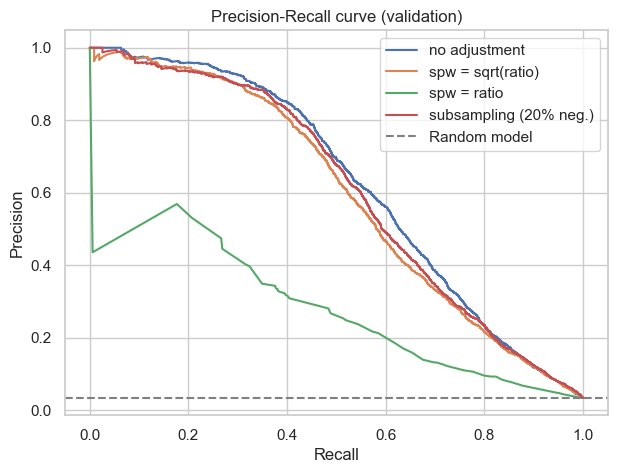

In [18]:
plt.figure(figsize=(7, 5))
for name, p in preds.items():
    prec, rec, _ = precision_recall_curve(y_valid, p)
    plt.plot(rec, prec, label=name)
plt.axhline(y_valid.mean(), color="gray", linestyle="--", label="Random model")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall curve (validation)"); plt.legend(); plt.show()

## 6. Conclusions

**Result:** no imbalance strategy outperforms the baseline without adjustment (PR-AUC 0.6172 ± 0.0040).
- `scale_pos_weight` = sqrt(ratio): 0.5936 ± 0.0014
- Undersampling (20% of negatives): 0.5960 ± 0.0070
- `scale_pos_weight` = ratio: 0.2920 ± 0.0132; early stopping halted training at iteration 1, so this configuration was not evaluated under comparable conditions.

The drops of ~0.02 in PR-AUC for the first two exceed the variation between seeds.

**Hypothesis (not verified):** LightGBM already handles imbalance well when optimizing for ranking; reweighting or undersampling distorts the signal without adding information.

**Decision:** the model without adjustment is kept. This also leaves the probabilities undistorted, which simplifies choosing the threshold by cost.

**Limitations:** hyperparameters not tuned; SMOTE was not tested (unsuitable due to missing values and categorical features), nor were other weighting variants.